# GISPR Module 8 — Tying It Together: End-to-End Workflows, GDAL, QGIS, GeoLibre & Google Earth Engine

**Course:** GIS Spatial Analysis with Python and R (GISPR)
**Module:** 8 — Integration, GDAL, and the Platform Landscape
**Builds on:** Modules 3–4 (vector), Modules 5–6 (raster), Module 7 (visualization)

---

### What you'll accomplish this module

By the end of this notebook you'll be able to:

| # | Learning outcome | Where |
|---|---|---|
| 1 | Integrate vector processing, raster analysis, and visualization into one repeatable, end-to-end spatial data science workflow | Sections 1, 6 |
| 2 | Execute GDAL operations at the command line — format conversion, reprojection, clipping — and explain how GDAL underpins `rasterio` (Python) and `terra` / `sf` (R) | Sections 2–4 |
| 3 | Compare QGIS, GeoLibre, Google Earth Engine, and programmatic Python/R workflows, and choose the right tool for a given task | Sections 5, 7 |

### Kernel reminder

- 🔵 **`[R]`** cells — switch kernel to **R** before running
- 🟢 **`[Python]`** cells — switch kernel to **Python 3** (or your cloned ArcGIS Pro env) before running
- 📋 **`[Terminal]`** cells — paste the command into your terminal / Anaconda Prompt, **not** in a notebook cell

> **The framing problem for this module:**
> A county wants to plant trees where they'll do the most good. Which neighborhoods are:
1) hottest in summer
2) have the least tree canopy
3) are most socially vulnerable?

> Answering that needs raster data (land-surface temperature, canopy), vector data (neighborhoods, demographics), integration (zonal statistics + ranking), and a map to communicate it — the whole course, in one pipeline. Tonight you wire it together, add GDAL as the engine underneath it, and also explore other GIS tools (QGIS, GeoLibre, Earth Engine) that sit alongside Python and R.

> **Nothing here is new spatial theory.** Module 8 is the wiring diagram for skills you already have, plus GDAL and the platform choices that make each stage faster. If you can name the seven stages below and which module taught each one, you're ready for tonight's lab.

> **📌 This lab is optional extra credit.** From Module 8 on, the labs are **building blocks for your final project**. You're strongly encouraged to work through this one, since the end-to-end pipeline and GDAL patterns here are what most projects reuse. **Submitting the lab deliverables is optional** and counts as **extra credit** toward your final grade (see the end of this notebook). Your next required project milestone is the **Final Project Proposal**, due as Module 9's homework; Section 6, Option 4 gives you a head start on it.


---
## Section 1 — Anatomy of an End-to-End Workflow

Most projects — yours, ours, a consultant's — reduce to these same seven stages. Each can be automated.

| Stage | What happens | Module(s) | Typical tool |
|---|---|---|---|
| 1. Acquire | Download / API / DB | M2 | requests, ArcGIS API, Earth Engine |
| 2. Prepare | Format conversion, CRS, clean | M3, **M8 (GDAL)** | GDAL / OGR |
| 3. Vector ops | Buffer, clip, join | M4 | GeoPandas, sf |
| 4. Raster ops | Map algebra, zonal, warp | M5–6 | rasterio, terra |
| 5. Integrate | Combine, rank, model | M6–8 | pandas, dplyr |
| 6. Visualize | Static, interactive | M7 | matplotlib/tmap, folium/leaflet |
| 7. Communicate | Map, report, repo | M8+ | Quarto, GitHub |

**Reproducibility lives in the arrows.** Each hand-off between stages is code, not a click — so a script that runs stages 1→7 is one command to re-run when next quarter's data drops, instead of forty clicks you half-remember.

### Tonight's scenario — Heat-Equity Screening

| Stage | This scenario |
|---|---|
| Acquire | Landsat summer land-surface temperature + NLCD canopy (raster); census block groups + a social-vulnerability index, or SVI (vector) |
| Prepare | Reproject everything to one projected CRS; clip rasters to the county boundary |
| Analyze | Zonal statistics — mean temperature and % canopy per block group |
| Integrate | Join demographics; rank block groups into a priority score |
| Communicate | A static map for the report, an interactive map for stakeholders |

The scenario is EJ-flavored on purpose — it mirrors the kind of screening EPA and local governments actually run (EJScreen, the Climate & Economic Justice Screening Tool). Every section from here builds one piece of this pipeline.

---
## Section 2 — GDAL: The Engine Under Everything

You've been using GDAL all along. When you called `rasterio.open()` in Module 5 or `rast()` in `terra`, GDAL did the actual reading. It's the C/C++ translation layer behind 200+ geospatial formats — GeoTIFF, IMG, NetCDF, GeoPackage, Shapefile, File Geodatabase, Cloud-Optimized GeoTIFF, and more.

| Library | Language | Layer |
|---|---|---|
| GDAL + PROJ + GEOS | C/C++ | The engine — format I/O, projections, geometry |
| `rasterio`, GeoPandas / Fiona | Python | Thin wrappers over GDAL |
| `terra`, `sf` | R | Thin wrappers over GDAL |
| QGIS, ArcGIS, PostGIS | Desktop / database | All call GDAL too |

- **PROJ handles projections.** Every reproject you've run — `st_transform()`, `.to_crs()`, `gdalwarp` — is PROJ, bundled with GDAL.
- **GEOS handles geometry.** Buffer, intersection, and the other geometry operations from Module 4 run through GEOS.

So why drop to the command line at all, when your Python/R functions already wrap GDAL? For fast, scriptable data prep with no notebook needed — convert a folder of rasters, reproject, and clip in a one-liner. That's next.

In [1]:
# [Python] Confirm GDAL is the engine underneath rasterio
import rasterio

print("rasterio version:", rasterio.__version__)
print("GDAL version (via rasterio):", rasterio.__gdal_version__)

# Every rasterio driver name below is a GDAL driver name — same list gdalinfo --formats prints
with rasterio.Env() as env:
    drivers = rasterio.drivers.raster_driver_extensions()
print("\nA few formats rasterio/GDAL both read and write:")
for ext in ["tif", "img", "gpkg", "nc"]:
    print(f"  .{ext:<4} -> {drivers.get(ext, 'driver not registered in this build')}")


rasterio version: 1.5.2
GDAL version (via rasterio): 3.12.2

A few formats rasterio/GDAL both read and write:
  .tif  -> GTiff
  .img  -> HFA
  .gpkg -> GPKG
  .nc   -> netCDF


---
## Section 3 — GDAL at the Command Line

The same three operations — inspect, convert, reproject/clip — done the GDAL way and the library way. Learn the CLI once and it works everywhere: bash, Makefiles, CI, Docker.

We'll build the synthetic heat-equity rasters in Section 6, then run these exact commands against them. For now, read each command and match it to its rasterio/terra equivalent below.

### 3a — GDAL command-line reference

In [2]:
# [Terminal] GDAL / OGR command-line reference — paste into a terminal, not a notebook cell

# 1 — Inspect: CRS, extent, bands, dtype, NoData
# gdalinfo lst_summer.tif

# 2 — Convert format (IMG -> compressed GeoTIFF)
# gdal_translate -of GTiff -co COMPRESS=DEFLATE canopy.img canopy.tif

# 3 — Reproject + resample to 30 m, UTM 10N
# gdalwarp -t_srs EPSG:32610 -tr 30 30 -r bilinear lst_summer.tif lst_utm.tif

# 4 — Clip a raster to a county polygon
# gdalwarp -cutline county.gpkg -crop_to_cutline lst_utm.tif lst_county.tif

# 5 — Rasterize a vector field to a grid
# gdal_rasterize -a svi -tr 30 30 blockgroups.gpkg svi.tif

# Vector conversion / reprojection uses ogr2ogr, GDAL's vector-side sibling
# ogr2ogr -t_srs EPSG:32610 bg_utm.gpkg blockgroups.shp

# GDAL 3.11+ adds a unified 'gdal' program: gdal raster info, gdal raster reproject,
# gdal vector convert. The classic tools above still work everywhere and fill most
# tutorials and Stack Overflow answers, so learn them first.

# Classic gotcha: -t_srs is the TARGET srs; -s_srs is the source. Mixing them up
# silently reprojects into the wrong CRS instead of erroring.


### 3b — The same three operations in Python (`rasterio`)

In [3]:
# [Python] rasterio equivalents of gdalinfo / gdalwarp / gdal_translate
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.mask import mask as rio_mask

# gdalinfo -> just open it and read the profile
# with rasterio.open('lst_summer.tif') as src:
#     print(src.crs, src.bounds, src.res, src.dtypes)

# gdal_translate (format conversion) -> read profile, change driver/options, write
# with rasterio.open('canopy.img') as src:
#     profile = src.profile
#     profile.update(driver='GTiff', compress='DEFLATE')
#     with rasterio.open('canopy.tif', 'w', **profile) as dst:
#         dst.write(src.read())

# gdalwarp (reproject) -> rasterio.warp.calculate_default_transform + reproject
# with rasterio.open('lst_summer.tif') as src:
#     transform, width, height = calculate_default_transform(
#         src.crs, 'EPSG:32610', src.width, src.height, *src.bounds, resolution=30)
#     profile = src.profile.copy()
#     profile.update(crs='EPSG:32610', transform=transform, width=width, height=height)
#     with rasterio.open('lst_utm.tif', 'w', **profile) as dst:
#         reproject(source=rasterio.band(src, 1), destination=rasterio.band(dst, 1),
#                    src_transform=src.transform, src_crs=src.crs,
#                    dst_transform=transform, dst_crs='EPSG:32610',
#                    resampling=Resampling.bilinear)

# gdalwarp -cutline -crop_to_cutline (clip) -> rasterio.mask.mask
# import geopandas as gpd
# county = gpd.read_file('county.gpkg')
# with rasterio.open('lst_utm.tif') as src:
#     clipped, transform = rio_mask(src, county.geometry, crop=True)

print("See the commented cells above — each one is the library-side twin of a")
print("gdalinfo / gdal_translate / gdalwarp command from 3a. We'll run the real")
print("versions against synthetic data in Section 6.")


See the commented cells above — each one is the library-side twin of a
gdalinfo / gdal_translate / gdalwarp command from 3a. We'll run the real
versions against synthetic data in Section 6.


### 3c — The same three operations in R (`terra` / `sf`)

In [4]:
# [R] terra / sf equivalents of gdalinfo / gdalwarp / gdal_rasterize
library(terra)
library(sf)

# gdalinfo -> just load it
# r <- rast('lst_summer.tif')
# r                              # prints CRS, extent, resolution, dtype

# gdalwarp reproject -> project()
# r2 <- project(r, 'EPSG:32610', method = 'bilinear')

# gdalwarp -cutline -crop_to_cutline -> crop() + mask()
# co <- vect('county.gpkg')
# clipped <- crop(r2, co, mask = TRUE)

# gdal_rasterize -> rasterize()
# bg <- vect('blockgroups.gpkg')
# svi_raster <- rasterize(bg, r2, field = 'svi')

# ogr2ogr reproject (vector) -> st_transform()
# bg_utm <- st_transform(st_read('blockgroups.shp', quiet = TRUE), 32610)

cat("terra and sf call GDAL under the hood for every one of these — project(),")
cat("crop(), rasterize(), and st_transform() are R's names for the same GDAL/PROJ\n")
cat("operations gdalwarp and gdal_rasterize run at the command line.\n")


NameError: name 'library' is not defined

### 3d — Calling GDAL from inside a Python/R pipeline

GDAL CLI and Python/R aren't rivals — they're layers. Spatial analysts typically use the GDAL binary for the heavy, format-level lifting, then stay in code for the logic. That keeps a pipeline scriptable end to end without giving up GDAL's tuned, streaming C++ speed for big files.

In [6]:
# [Python] Put the ArcGIS_Clone GDAL tools on this kernel's PATH
import os
GDAL_BIN = r"C:\Users\Jordan\AppData\Local\ESRI\conda\envs\ArcGIS_Clone\Library\bin"
os.environ["PATH"] = GDAL_BIN + os.pathsep + os.environ["PATH"]
os.environ["PROJ_LIB"]  = r"C:\Users\Jordan\AppData\Local\ESRI\conda\envs\ArcGIS_Clone\Library\share\proj"
os.environ["GDAL_DATA"] = r"C:\Users\Jordan\AppData\Local\ESRI\conda\envs\ArcGIS_Clone\Library\share\gdal"
print("gdalinfo found at:", __import__("shutil").which("gdalinfo"))

gdalinfo found at: C:\Users\Jordan\AppData\Local\ESRI\conda\envs\ArcGIS_Clone\Library\bin\gdalinfo.EXE


In [8]:
# [Python] Shelling out to GDAL from inside a pipeline with subprocess
import subprocess
import shutil

def gdal_available() -> bool:
    '''Return True if the gdalinfo binary is on PATH.'''
    return shutil.which("gdalinfo") is not None

def run_gdalwarp(src_path, dst_path, t_srs="EPSG:32610", tr=(30, 30), resampling="bilinear"):
    '''
    Wrap gdalwarp as a Python function — the pattern behind
    'a Python script that shells out to gdalwarp for the heavy prep.'
    '''
    cmd = [
        "gdalwarp", "-t_srs", t_srs,
        "-tr", str(tr[0]), str(tr[1]),
        "-r", resampling,
        src_path, dst_path,
    ]
    print("Running:", " ".join(cmd))
    return subprocess.run(cmd, check=True, capture_output=True, text=True)

if gdal_available():
    print("GDAL command-line tools found on PATH — run_gdalwarp() will work as written.")
else:
    print("GDAL command-line tools not found on PATH in this environment.")
    print("This is expected in many hosted Jupyter kernels — the function above is")
    print("still the pattern to use once GDAL is installed (conda install -c conda-forge gdal).")


GDAL command-line tools found on PATH — run_gdalwarp() will work as written.


### When to drop to the command line vs. stay in Python/R

| Reach for GDAL CLI when… | Stay in Python / R when… |
|---|---|
| Batch-processing a folder of files (bash loop or GNU parallel) | The step needs conditional logic, loops over analysis, or a model |
| One-off format conversion or reprojection — no notebook worth spinning up | You're combining vector + raster + tables in one reproducible flow |
| Files are huge and you want GDAL's tuned, streaming C++ speed | Results feed a plot, a report, or a dashboard in the same document |
| Wiring a step into a Makefile, shell script, CI job, or Dockerfile | You want unit-testable, version-controlled analysis others can re-run |
| You just need to inspect a file fast (`gdalinfo` / `ogrinfo`) | You need ArcPy / ArcGIS API integration alongside open-source steps |

In practice you mix them: a Python script that shells out to `gdalwarp` for the heavy prep, then does the analysis in `rasterio` — exactly what `run_gdalwarp()` above sets up. The pipeline is the boss; the CLI is one worker.

---
## Section 4 — The Platform Landscape

Four other ways GIS work beyond your notebook. Each is a **category**, not just a product — know what each is best at, and where it hurts.

| Platform | Category | Best at | Watch out for |
|---|---|---|---|
| **QGIS** | Desktop GIS | Interactive exploration, cartography, quick QA of scripted output, no-code teammates. Free, open-source — the open ArcGIS Pro, with a Processing Toolbox, Model Builder, and a PyQGIS console. | Manual clicks aren't reproducible unless you script them. |
| **GeoLibre** | Cloud-native GIS | Lightweight cloud data, quick sharing, teams without local installs. Browser-based, reads COGs, GeoParquet, and STAC directly — no download, no install. Share a live map by URL. | Newer ecosystem; you're working against data in the cloud, not on disk. |
| **Google Earth Engine** | Cloud-scale analysis | Large-area / long time-series remote sensing without downloading data. Planetary-scale, petabyte imagery catalog (Landsat, Sentinel, MODIS, climate). Server-side compute; JavaScript editor + Python `ee` API. | Client vs. server execution model; harder to reproduce fully outside Google. |
| **Python / R** | Programmatic anchor | The pipeline that ties everything together, end to end. Full control, reproducible, version-controlled, automatable. Integrates ESRI (`arcpy`, ArcGIS API) and every open-source library — and can call all three tools above. | More upfront code than clicking; that's the price of reproducibility. |

### Choosing the right tool

There's no single best tool — only the best fit for the task in front of you.

| If you need to… | Reach for |
|---|---|
| Explore spatial data, make a map, hand it to a non-coder | QGIS |
| Batch-convert / reproject / clip a pile of files, fast | GDAL command line |
| Analyze decades of imagery over a whole region | Google Earth Engine |
| Explore cloud-native data (COG / STAC / GeoParquet) and share a link to a functional browser-based GIS | GeoLibre |
| Build a reproducible, automated, integrated pipeline — data in to decisions out | Python / R (the anchor) |

**The anchor mindset:** pick Python or R as home base, and call out to QGIS, GDAL, Earth Engine, or GeoLibre when they're the better worker for one stage. One pipeline, many tools.

---
## Section 5 — Guided Lab: Build the Heat-Equity Screening Pipeline

**Scenario:** A county wants to plant trees where they'll do the most good. Your job: rank every block group by summer heat, tree-canopy loss, and social vulnerability, then hand the planning office a map.

Work through steps 1–5 in order. Data note: to keep this notebook self-contained and download-free, we generate synthetic-but-realistic rasters and block-group polygons in step 1 — swap in your county's real Landsat LST, NLCD canopy, and block-group/SVI files and the rest of the pipeline runs unchanged.

**Goal:** a ranked priority map, plus a `run_pipeline()` function you could point at next summer's data.

### Step 1a — Build the synthetic study area (so this notebook runs standalone)

In [9]:
# [Python] Step 1 — synthetic county, LST raster, canopy raster, and block groups with SVI
# A fictional mid-size city: a hot downtown core, a cooler river corridor and parks,
# leafy neighborhoods at the edges, and irregular block groups that are smaller where
# population is denser -- the same shapes and textures you'd see in real Landsat/NLCD data.
import os
import numpy as np
import rasterio
from rasterio.transform import from_origin
import geopandas as gpd
from shapely.geometry import Point, Polygon, MultiPoint, box
from shapely.ops import voronoi_diagram

os.makedirs("output", exist_ok=True)
rng = np.random.default_rng(8)

# --- Raster grid: 6 km x 6 km at 30 m (Landsat / NLCD resolution), UTM 10N ---
ncols, nrows, cellsize = 200, 200, 30
xmin, ymax = 500000, 5275000     # arbitrary UTM 10N origin
transform = from_origin(xmin, ymax, cellsize, cellsize)
crs = "EPSG:32610"
nodata = -9999.0

# Cell-center coordinates in km from the grid's top-left corner
xs = (np.arange(ncols) + 0.5) * cellsize / 1000
ys = (np.arange(nrows) + 0.5) * cellsize / 1000
X, Y = np.meshgrid(xs, ys)

def smooth_noise(sigma_cells, scale=1.0):
    """Spatially correlated noise: white noise blurred with a Gaussian kernel (numpy only)."""
    field = rng.normal(0, 1, (nrows, ncols))
    k = np.arange(-3 * sigma_cells, 3 * sigma_cells + 1)
    kernel = np.exp(-0.5 * (k / sigma_cells) ** 2)
    kernel /= kernel.sum()
    field = np.apply_along_axis(lambda r: np.convolve(r, kernel, mode="same"), 1, field)
    field = np.apply_along_axis(lambda c: np.convolve(c, kernel, mode="same"), 0, field)
    return scale * field / field.std()

# Urban intensity (0-1): downtown core plus a secondary commercial center and a road corridor
core = np.exp(-(((X - 2.3) ** 2) / 1.8 + ((Y - 2.0) ** 2) / 1.2))
sub_center = 0.6 * np.exp(-(((X - 4.6) ** 2) + ((Y - 4.4) ** 2)) / 0.5)
arterial = 0.35 * np.exp(-((Y - (0.55 * X + 0.8)) ** 2) / 0.04)      # a diagonal highway
urban = np.clip(core + sub_center + arterial + smooth_noise(12, 0.08), 0, 1)

# A meandering river: distance (km) from each cell to the river centerline
river_y = 3.6 + 0.45 * np.sin(X * 1.3) + 0.15 * np.sin(X * 3.1)
dist_river = np.abs(Y - river_y)
river_cool = np.exp(-dist_river / 0.25)                              # strongest within ~250 m

# Parks: a few cool, leafy patches of different sizes
parks = np.zeros_like(X)
for px, py, r in [(1.2, 1.1, 0.25), (3.4, 1.5, 0.18), (5.2, 2.2, 0.35), (0.9, 5.1, 0.4), (3.0, 5.4, 0.22)]:
    parks = np.maximum(parks, np.exp(-((X - px) ** 2 + (Y - py) ** 2) / r ** 2))

# Percent tree canopy (0-100): low downtown, high in parks, along the river, and at the leafy edges
canopy = (
    55 - 45 * urban + 35 * parks + 20 * river_cool
    + smooth_noise(4, 6) + rng.normal(0, 3, (nrows, ncols))
)
canopy = np.clip(canopy, 0, 95)

# Summer land-surface temperature (°C): driven by urban intensity, cooled by canopy and the river
lst = (
    27.0 + 9.0 * urban - 0.07 * canopy - 3.0 * river_cool
    + smooth_noise(6, 0.8) + rng.normal(0, 0.3, (nrows, ncols))
)

# --- County boundary: an irregular polygon inside the grid (cells outside become NoData) ---
angles = np.linspace(0, 2 * np.pi, 40, endpoint=False)
radii = 2.75 + 0.18 * np.sin(3 * angles + 0.5) + 0.10 * np.sin(7 * angles) + rng.normal(0, 0.04, 40)
county_geom = Polygon([
    (xmin + (3.0 + r * np.cos(a)) * 1000, ymax - (3.0 + r * np.sin(a)) * 1000)
    for a, r in zip(angles, radii)
])
county = gpd.GeoDataFrame({"name": ["Fictional County"]}, geometry=[county_geom], crs=crs)
county.to_file("output/county.gpkg", driver="GPKG", layer="county")

cx = xmin + X * 1000
cy = ymax - Y * 1000
inside = gpd.GeoSeries(gpd.points_from_xy(cx.ravel(), cy.ravel()), crs=crs).within(county_geom).to_numpy()
inside = inside.reshape(nrows, ncols)

def write_raster(path, array):
    out = np.where(inside, array, nodata).astype("float32")
    profile = dict(
        driver="GTiff", height=nrows, width=ncols, count=1,
        dtype="float32", crs=crs, transform=transform, nodata=nodata,
    )
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(out, 1)

write_raster("output/lst_summer.tif", lst)
write_raster("output/canopy.tif", canopy)
print("Wrote output/lst_summer.tif and output/canopy.tif")
print(f"  Grid: {nrows} x {ncols} cells @ {cellsize} m, CRS {crs}; cells outside the county = NoData")

# --- Block groups: irregular Voronoi polygons, smaller (denser) toward downtown ---
seeds = []
while len(seeds) < 36:
    x, y = rng.uniform(0.2, 5.8, 2)
    density = 0.25 + 0.75 * np.exp(-(((x - 2.3) ** 2) / 3.0 + ((y - 2.0) ** 2) / 2.0))
    if rng.uniform() < density:
        seeds.append(Point(xmin + x * 1000, ymax - y * 1000))

cells = voronoi_diagram(MultiPoint(seeds), envelope=box(*county_geom.buffer(2000).bounds))
polys = [p.intersection(county_geom) for p in cells.geoms]
polys = [p for p in polys if p.area > 50_000]          # drop slivers under 5 ha

blockgroups = gpd.GeoDataFrame(geometry=polys, crs=crs)
# Number block groups north-to-south, west-to-east, like a reader scanning the map
c = blockgroups.geometry.centroid
blockgroups = blockgroups.iloc[np.lexsort((c.x.round(-2), -c.y.round(-3)))].reset_index(drop=True)
blockgroups.insert(0, "bg_id", [f"BG-{i + 1:02d}" for i in range(len(blockgroups))])

# SVI (0-1): higher near downtown and along the highway, plus an older neighborhood
# by the river that the urban-intensity surface alone wouldn't predict
c = blockgroups.geometry.centroid
bx, by = (c.x - xmin) / 1000, (ymax - c.y) / 1000
svi = (
    0.25
    + 0.40 * np.exp(-(((bx - 2.3) ** 2) / 2.5 + ((by - 2.0) ** 2) / 2.0))
    + 0.20 * np.exp(-((by - (0.55 * bx + 0.8)) ** 2) / 0.3)
    + 0.35 * np.exp(-(((bx - 1.0) ** 2) + ((by - 3.9) ** 2)) / 0.4)
    + rng.normal(0, 0.07, len(blockgroups))
)
blockgroups["svi"] = np.clip(svi, 0.02, 0.98).round(2)

blockgroups.to_file("output/blockgroups.gpkg", driver="GPKG", layer="blockgroups")
print(f"\nWrote output/blockgroups.gpkg -- {len(blockgroups)} block groups, SVI range "
      f"{blockgroups.svi.min():.2f}-{blockgroups.svi.max():.2f}")

Wrote output/lst_summer.tif and output/canopy.tif
  Grid: 200 x 200 cells @ 30 m, CRS EPSG:32610; cells outside the county = NoData

Wrote output/blockgroups.gpkg -- 34 block groups, SVI range 0.19-0.87


### Step 1b — (Optional) Swap in real data with `USE_REAL_DATA`

The cell below is **off by default** (`USE_REAL_DATA = False`), so the lab runs on the synthetic data from Step 1a. You will need the `pygris` and `pyarrow` libraries as well to use this - install with `conda install pygris pyarrow -c conda-forge`. Turn it on to rebuild the same four files from real sources for King County, WA:

| Layer | Source |
|---|---|
| County + block groups | U.S. Census Bureau TIGER/Line cartographic boundaries, via `pygris` |
| Social vulnerability | CDC/ATSDR SVI 2022 (`RPL_THEMES`). SVI is published for **tracts**, not block groups, so each block group gets its tract's score (joined on the first 11 digits of the GEOID). |
| Summer land-surface temperature | Landsat 8/9 Collection 2 Level-2, band `ST_B10` (one clear July–August scene), converted to °C |
| Tree canopy | NLCD Tree Canopy Cover from the USDA Forest Service (MRLC) |

The two rasters are downloaded by hand first (see the notes at the top of the cell); the cell then reprojects and clips them with `gdalwarp`, exactly the commands from Section 3a.

In [10]:
# [Python] Step 1b (optional) -- swap in REAL data for King County, WA
# Leave USE_REAL_DATA = False to keep the synthetic study area from Step 1a.
# Set it to True to overwrite the Step 1a files in output/ with real data; every later
# step reads the same file names and columns, so the rest of the pipeline runs unchanged.
#
# One-time setup:  conda install pygris pyarrow -c conda-forge
# Rasters you download yourself first (put both in data/):
#   data/lst_raw.tif    -- ONE Landsat 8/9 Collection 2 Level-2 summer scene, band ST_B10
#                          (EarthExplorer or Planetary Computer; WRS-2 path 46 / row 27 covers Seattle)
#   data/canopy_raw.tif -- NLCD Tree Canopy Cover (USFS), latest year, clipped to roughly King County
#                          (MRLC download tool at mrlc.gov lets you draw a box)

USE_REAL_DATA = False

STATE, COUNTY, YEAR = "WA", "King", 2022
CRS = "EPSG:32610"   # UTM 10N, same as the synthetic data
SVI_URL = ("https://data.source.coop/cboettig/social-vulnerability/2022/"
           "SVI2022_US_tract.parquet")   # CDC/ATSDR SVI 2022, tract level (cloud mirror)

if not USE_REAL_DATA:
    print("USE_REAL_DATA = False -- keeping the synthetic Step 1a data.")
else:
    import os, subprocess, urllib.request
    import numpy as np
    import pandas as pd
    import geopandas as gpd
    import rasterio
    from pygris import block_groups, counties

    os.makedirs("output", exist_ok=True)
    os.makedirs("data", exist_ok=True)

    # --- 1. County boundary + block groups (Census TIGER cartographic boundaries) ---
    county = counties(state=STATE, cb=True, year=YEAR)
    county = county[county["NAME"] == COUNTY].to_crs(CRS)[["NAME", "geometry"]]
    county = county.rename(columns={"NAME": "name"})
    county.to_file("output/county.gpkg", driver="GPKG", layer="county")

    bg = block_groups(state=STATE, county=COUNTY, cb=True, year=YEAR).to_crs(CRS)
    bg = bg[bg["ALAND"] > 0]                    # drop water-only block groups
    bg["bg_id"] = bg["GEOID"].astype(str)
    bg["tract"] = bg["bg_id"].str[:11]          # first 11 digits of a block group GEOID = its tract

    # --- 2. SVI: tract-level only, so each block group inherits its tract's score ---
    svi_path = "data/SVI2022_US_tract.parquet"
    if not os.path.exists(svi_path):
        print("Downloading CDC/ATSDR SVI 2022 (tract level, ~national file)...")
        urllib.request.urlretrieve(SVI_URL, svi_path)
    svi = pd.read_parquet(svi_path)
    cols = {c.upper(): c for c in svi.columns}
    svi = svi[[cols["FIPS"], cols["RPL_THEMES"]]].copy()
    svi.columns = ["tract", "svi"]
    svi["tract"] = svi["tract"].astype(str).str.zfill(11)
    svi.loc[svi["svi"] < 0, "svi"] = np.nan     # CDC codes missing values as -999

    bg = bg.merge(svi, on="tract", how="left")
    print(f"Block groups: {len(bg)}  |  missing SVI: {bg['svi'].isna().sum()}")
    bg = bg.dropna(subset=["svi"])
    bg[["bg_id", "tract", "svi", "geometry"]].to_file(
        "output/blockgroups.gpkg", driver="GPKG", layer="blockgroups")

    # --- 3. Rasters: reproject + clip with gdalwarp (Section 3a), then convert units ---
    for f in ["data/lst_raw.tif", "data/canopy_raw.tif"]:
        if not os.path.exists(f):
            raise FileNotFoundError(f"{f} not found -- download it first (see the notes at the top of this cell).")

    def warp(src, dst, resampling, src_nodata):
        cmd = ["gdalwarp", "-overwrite", "-t_srs", CRS, "-tr", "30", "30", "-r", resampling,
               "-srcnodata", str(src_nodata), "-dstnodata", "-9999", "-ot", "Float32",
               "-cutline", "output/county.gpkg", "-crop_to_cutline", src, dst]
        subprocess.run(cmd, check=True)

    warp("data/lst_raw.tif", "output/lst_summer.tif", "bilinear", 0)    # Landsat ST fill = 0
    warp("data/canopy_raw.tif", "output/canopy.tif", "near", 255)        # TCC background = 255

    # Landsat C2 L2 surface temperature: Kelvin = DN * 0.00341802 + 149.0; then to deg C
    with rasterio.open("output/lst_summer.tif", "r+") as dst:
        a = dst.read(1)
        valid = a != -9999
        a[valid] = a[valid] * 0.00341802 + 149.0 - 273.15
        dst.write(a, 1)

    # NLCD TCC: 0-100 = percent canopy; 254 = non-processing area -> NoData
    with rasterio.open("output/canopy.tif", "r+") as dst:
        a = dst.read(1)
        a[a > 100] = -9999
        dst.write(a, 1)

    print("Wrote real-data versions of output/county.gpkg, output/blockgroups.gpkg,")
    print("output/lst_summer.tif, and output/canopy.tif -- continue with Step 2.")

USE_REAL_DATA = False -- keeping the synthetic Step 1a data.


### Step 2 — Prep with GDAL

In production this is where you'd reproject Landsat LST and NLCD canopy from their native CRS to a common UTM zone and clip both to the county boundary — the `gdalwarp` commands from Section 3a. Our synthetic rasters are already in UTM 10N and already county-sized, so we validate that instead of re-deriving it — the same `gdalinfo` sanity check you'd run first on real data.

In [11]:
# [Python] Step 2 -- validate CRS + extent alignment before doing any analysis
# (the "assert it before analysis" fix for the #1 lab stall: CRS drift)

import rasterio
import geopandas as gpd

with rasterio.open("output/lst_summer.tif") as lst_src:
    lst_crs, lst_bounds, lst_res = lst_src.crs, lst_src.bounds, lst_src.res

with rasterio.open("output/canopy.tif") as canopy_src:
    canopy_crs = canopy_src.crs

blockgroups = gpd.read_file("output/blockgroups.gpkg")
county = gpd.read_file("output/county.gpkg")

print("LST      CRS:", lst_crs, "| resolution:", lst_res, "| bounds:", lst_bounds)
print("Canopy   CRS:", canopy_crs)
print("Blockgrp CRS:", blockgroups.crs)
print("County   CRS:", county.crs)

all_match = len({str(lst_crs), str(canopy_crs), str(blockgroups.crs), str(county.crs)}) == 1
print("\nAll four layers share one CRS:", "YES" if all_match else "NO -- reproject before continuing")

# Real-data equivalent you'd run at the terminal first:
#   gdalwarp -t_srs EPSG:32610 -tr 30 30 -r bilinear lst_raw.tif lst_utm.tif
#   gdalwarp -cutline county.gpkg -crop_to_cutline lst_utm.tif lst_summer.tif
#   ogr2ogr -t_srs EPSG:32610 blockgroups.gpkg blockgroups_raw.shp


LST      CRS: EPSG:32610 | resolution: (30.0, 30.0) | bounds: BoundingBox(left=500000.0, bottom=5269000.0, right=506000.0, top=5275000.0)
Canopy   CRS: EPSG:32610
Blockgrp CRS: EPSG:32610
County   CRS: EPSG:32610

All four layers share one CRS: YES


LST      -- min: 17.6C  max: 37.4C  mean: 25.7C
Canopy   -- min: 0%  max: 94%  mean: 47%


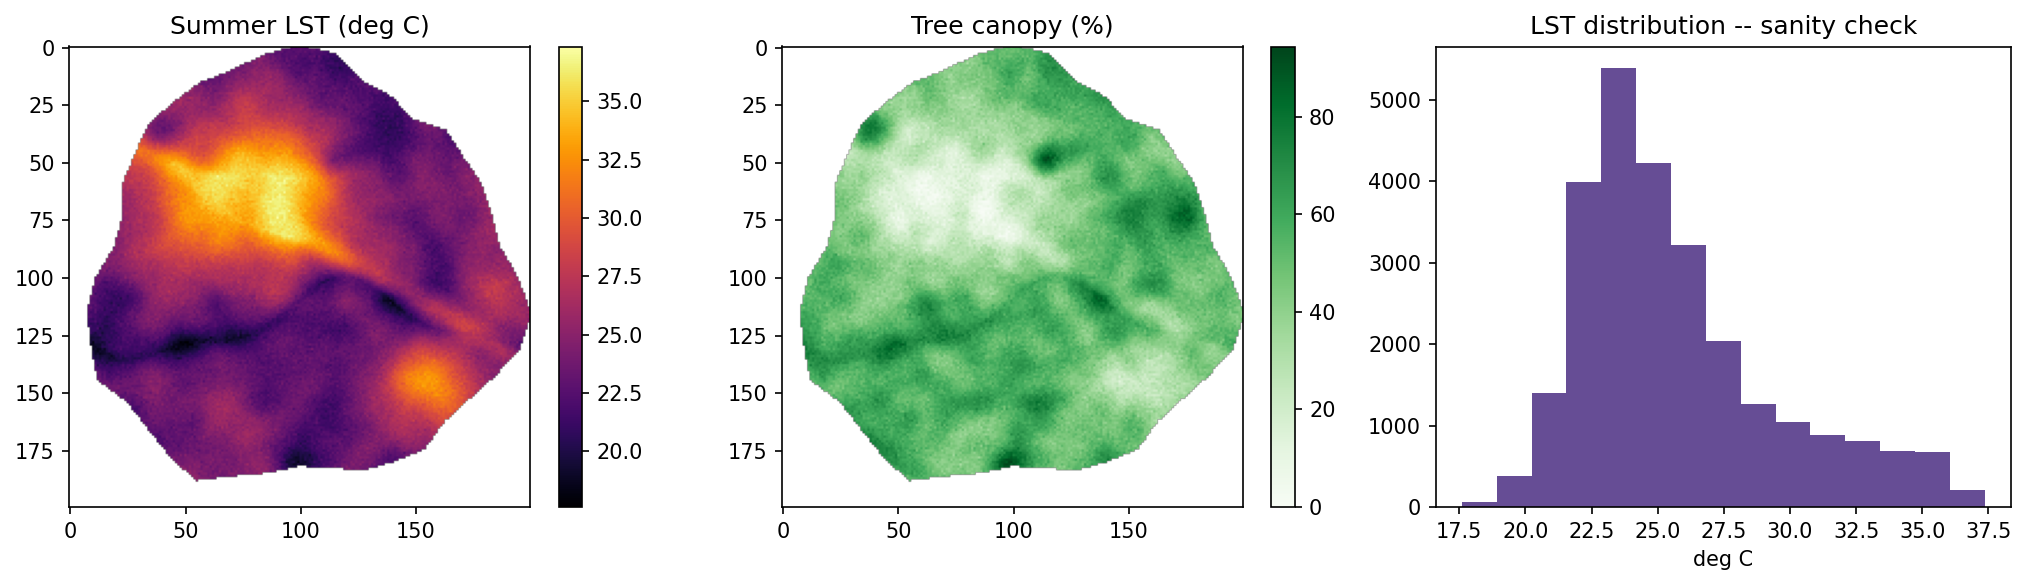


Saved output/step2_raster_qc.png


In [12]:
# [Python] Step 2 -- load rasters, mask NoData, sanity-check
import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open("output/lst_summer.tif") as src:
    lst = src.read(1, masked=True)
    lst_transform = src.transform

with rasterio.open("output/canopy.tif") as src:
    canopy = src.read(1, masked=True)

print("LST      -- min: {:.1f}C  max: {:.1f}C  mean: {:.1f}C".format(lst.min(), lst.max(), lst.mean()))
print("Canopy   -- min: {:.0f}%  max: {:.0f}%  mean: {:.0f}%".format(canopy.min(), canopy.max(), canopy.mean()))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

im0 = axes[0].imshow(lst, cmap="inferno")
axes[0].set_title("Summer LST (deg C)")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(canopy, cmap="Greens")
axes[1].set_title("Tree canopy (%)")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

axes[2].hist(lst.compressed(), bins=15, color="#4b2e83", alpha=0.85)
axes[2].set_title("LST distribution -- sanity check")
axes[2].set_xlabel("deg C")

plt.tight_layout()
plt.savefig("output/step2_raster_qc.png", dpi=150)
plt.show()
print("\nSaved output/step2_raster_qc.png")


### Step 3 — Zonal statistics

Summarize mean summer temperature and mean % canopy for each block-group polygon — the vector-meets-raster hand-off from Module 6.

In [13]:
# [Python] Step 3 -- zonal statistics per block group (mean LST, mean canopy)
# pip install rasterstats --break-system-packages   # if not already installed
from rasterstats import zonal_stats
import geopandas as gpd

blockgroups = gpd.read_file("output/blockgroups.gpkg")

lst_stats = zonal_stats("output/blockgroups.gpkg", "output/lst_summer.tif", stats="mean", nodata=-9999.0)
canopy_stats = zonal_stats("output/blockgroups.gpkg", "output/canopy.tif", stats="mean", nodata=-9999.0)

blockgroups["mean_lst"] = [round(s["mean"], 2) if s["mean"] is not None else None for s in lst_stats]
blockgroups["mean_canopy"] = [round(s["mean"], 1) if s["mean"] is not None else None for s in canopy_stats]

print(blockgroups[["bg_id", "svi", "mean_lst", "mean_canopy"]].to_string(index=False))
blockgroups.to_file("output/blockgroups.gpkg", driver="GPKG", layer="blockgroups")


bg_id  svi  mean_lst  mean_canopy
BG-01 0.58     28.20         42.0
BG-02 0.56     30.79         23.0
BG-03 0.43     25.52         42.1
BG-04 0.59     32.36         24.5
BG-05 0.35     23.34         53.9
BG-06 0.41     25.25         53.5
BG-07 0.38     21.96         56.0
BG-08 0.52     25.84         44.8
BG-09 0.68     28.62         36.1
BG-10 0.58     28.48         32.1
BG-11 0.72     32.71         14.8
BG-12 0.87     34.61         10.4
BG-13 0.65     32.01         21.3
BG-14 0.48     33.17         22.8
BG-15 0.26     25.36         46.9
BG-16 0.34     23.43         55.1
BG-17 0.26     23.56         62.2
BG-18 0.20     24.21         58.4
BG-19 0.53     22.45         55.7
BG-20 0.42     29.10         34.9
BG-21 0.48     27.06         41.5
BG-22 0.35     24.43         51.2
BG-23 0.70     30.97         26.6
BG-24 0.41     23.82         53.9
BG-25 0.46     25.34         50.0
BG-26 0.25     25.87         49.2
BG-27 0.63     21.85         62.7
BG-28 0.39     22.61         57.5
BG-29 0.42    

In [ ]:
# [R] Step 3 (R version) -- zonal statistics with terra::extract()
library(terra)
library(sf)

lst_r <- rast("output/lst_summer.tif")
canopy_r <- rast("output/canopy.tif")
bg <- vect("output/blockgroups.gpkg")

lst_means <- extract(lst_r, bg, fun = mean, na.rm = TRUE)
canopy_means <- extract(canopy_r, bg, fun = mean, na.rm = TRUE)

bg_df <- as.data.frame(bg)
bg_df$mean_lst <- round(lst_means[, 2], 2)
bg_df$mean_canopy <- round(canopy_means[, 2], 1)

print(bg_df[, c("bg_id", "svi", "mean_lst", "mean_canopy")])
# terra::extract() is the direct R equivalent of rasterstats.zonal_stats() --
# same GDAL/GEOS machinery underneath, different front door.


### Step 4 — Rank and join

Build a 0–1 priority score combining heat, low canopy, and high vulnerability, then sort to find the top-priority block groups for tree planting.

In [14]:
# [Python] Step 4 -- normalize each factor to 0-1 and combine into a priority score
import geopandas as gpd

blockgroups = gpd.read_file("output/blockgroups.gpkg")

def normalize(series, invert=False):
    lo, hi = series.min(), series.max()
    norm = (series - lo) / (hi - lo)
    return 1 - norm if invert else norm

blockgroups["heat_score"] = normalize(blockgroups["mean_lst"])
blockgroups["canopy_score"] = normalize(blockgroups["mean_canopy"], invert=True)   # low canopy -> high score
blockgroups["svi_score"] = normalize(blockgroups["svi"])

# Equal-weighted composite -- document your weighting choice in the final report
blockgroups["priority_score"] = (
    blockgroups["heat_score"] + blockgroups["canopy_score"] + blockgroups["svi_score"]
) / 3

ranked = blockgroups.sort_values("priority_score", ascending=False)
print(ranked[["bg_id", "mean_lst", "mean_canopy", "svi", "priority_score"]]
      .round(2).to_string(index=False))

ranked.to_file("output/blockgroups.gpkg", driver="GPKG", layer="blockgroups")
print(f"\nTop priority block group: {ranked.iloc[0].bg_id}  (score {ranked.iloc[0].priority_score:.2f})")


bg_id  mean_lst  mean_canopy  svi  priority_score
BG-12     34.61         10.4 0.87            1.00
BG-11     32.71         14.8 0.72            0.85
BG-13     32.01         21.3 0.65            0.75
BG-23     30.97         26.6 0.70            0.72
BG-04     32.36         24.5 0.59            0.71
BG-14     33.17         22.8 0.48            0.69
BG-02     30.79         23.0 0.56            0.67
BG-09     28.62         36.1 0.68            0.59
BG-10     28.48         32.1 0.58            0.56
BG-01     28.20         42.0 0.58            0.49
BG-20     29.10         34.9 0.42            0.48
BG-21     27.06         41.5 0.48            0.41
BG-08     25.84         44.8 0.52            0.38
BG-29     26.31         43.5 0.42            0.35
BG-03     25.52         42.1 0.43            0.34
BG-25     25.34         50.0 0.46            0.30
BG-34     27.68         41.6 0.19            0.29
BG-06     25.25         53.5 0.41            0.26
BG-19     22.45         55.7 0.53            0.23


### Step 5 — Map it

A static choropleth for the report, and an interactive map for stakeholders to explore.

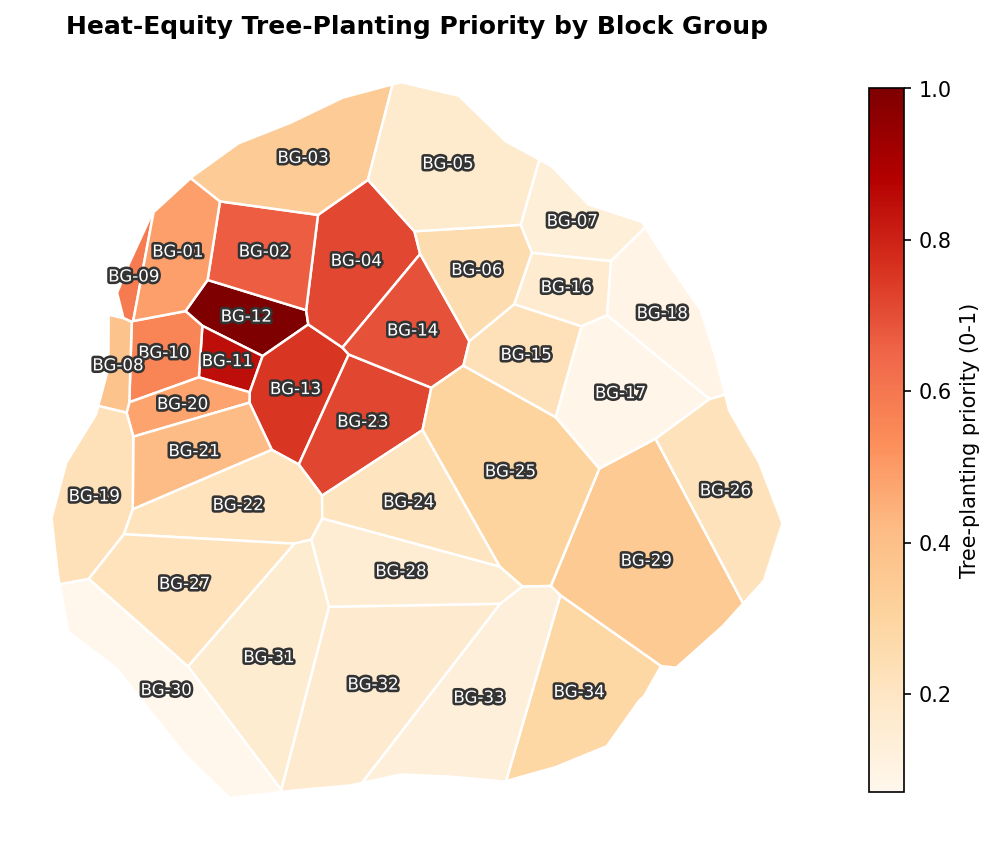

Saved output/priority_map_static.png


In [15]:
# [Python] Step 5a -- static priority map for the report
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

blockgroups = gpd.read_file("output/blockgroups.gpkg")

fig, ax = plt.subplots(figsize=(7, 7))
blockgroups.plot(
    column="priority_score", cmap="OrRd", legend=True,
    edgecolor="white", linewidth=1.2, ax=ax,
    legend_kwds={"label": "Tree-planting priority (0-1)", "shrink": 0.7},
)
# White text with a dark outline reads clearly across the whole OrRd ramp --
# a plain gray label (or plain white) loses contrast at one end or the other.
label_effects = [pe.withStroke(linewidth=2.5, foreground="#333333")]
if len(blockgroups) <= 50:   # labels help on the 16 synthetic block groups; skip for real counties
    for _, row in blockgroups.iterrows():
        c = row.geometry.centroid
        ax.annotate(
            row.bg_id, (c.x, c.y), ha="center", va="center",
            fontsize=8, color="white", path_effects=label_effects,
        )

ax.set_title("Heat-Equity Tree-Planting Priority by Block Group", fontsize=12, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.savefig("output/priority_map_static.png", dpi=150)
plt.show()
print("Saved output/priority_map_static.png")


In [16]:
# [Python] Step 5b -- interactive map for stakeholders (folium)
# pip install folium --break-system-packages   # if not already installed
import geopandas as gpd
import folium

blockgroups_utm = gpd.read_file("output/blockgroups.gpkg")           # projected CRS -- safe for centroid
center_pt = blockgroups_utm.union_all().centroid                     # compute center before reprojecting
blockgroups = blockgroups_utm.to_crs(epsg=4326)                      # folium needs WGS 84
center_pt_wgs84 = gpd.GeoSeries([center_pt], crs=blockgroups_utm.crs).to_crs(epsg=4326).iloc[0]

center = [center_pt_wgs84.y, center_pt_wgs84.x]
m = folium.Map(location=center, zoom_start=13,
               tiles="Esri.WorldGrayCanvas")   # CARTO tiles now need an API key; Esri's don't
minx, miny, maxx, maxy = blockgroups.total_bounds
m.fit_bounds([[miny, minx], [maxy, maxx]])     # zooms correctly for synthetic or real data

folium.Choropleth(
    geo_data=blockgroups,
    data=blockgroups,
    columns=["bg_id", "priority_score"],
    key_on="feature.properties.bg_id",
    fill_color="OrRd",
    fill_opacity=0.75,
    line_opacity=0.6,
    legend_name="Tree-planting priority (0-1)",
).add_to(m)

folium.GeoJson(
    blockgroups,
    tooltip=folium.GeoJsonTooltip(fields=["bg_id", "mean_lst", "mean_canopy", "svi", "priority_score"]),
).add_to(m)

m.save("output/priority_map_interactive.html")
print("Saved output/priority_map_interactive.html -- open it in a browser to explore")
m

Saved output/priority_map_interactive.html -- open it in a browser to explore


### Try it yourself

Wrap steps 1–5 into a single `run_pipeline(county, year)` function so next summer's data is one call away. That's the whole point of the module — reproducibility lives in the arrows, and a function is the arrow made concrete.

In [17]:
# [Python] Try it yourself -- a reusable run_pipeline() wrapping steps 1-5
import geopandas as gpd
import rasterio
from rasterstats import zonal_stats

def normalize(series, invert=False):
    lo, hi = series.min(), series.max()
    norm = (series - lo) / (hi - lo)
    return 1 - norm if invert else norm

def run_pipeline(county_name, lst_path, canopy_path, blockgroups_path, out_gpkg):
    '''
    Run the heat-equity screening pipeline end to end: zonal stats -> rank -> export.
    Assumes lst_path, canopy_path, and blockgroups_path are already reprojected and
    clipped (Step 1 -- do that with gdalwarp before calling this).
    '''
    print(f"[1/4] Loading block groups for {county_name}")
    bg = gpd.read_file(blockgroups_path)

    print("[2/4] Zonal statistics")
    bg["mean_lst"] = [s["mean"] for s in zonal_stats(bg, lst_path, stats="mean", nodata=-9999.0)]
    bg["mean_canopy"] = [s["mean"] for s in zonal_stats(bg, canopy_path, stats="mean", nodata=-9999.0)]

    print("[3/4] Scoring and ranking")
    bg["priority_score"] = (
        normalize(bg["mean_lst"]) + normalize(bg["mean_canopy"], invert=True) + normalize(bg["svi"])
    ) / 3
    bg = bg.sort_values("priority_score", ascending=False)

    print(f"[4/4] Writing {out_gpkg}")
    bg.to_file(out_gpkg, driver="GPKG", layer="priority")
    print(f"\nDone. Top priority block group: {bg.iloc[0].bg_id} (score {bg.iloc[0].priority_score:.2f})")
    return bg

# Re-run the whole pipeline in one call on the same synthetic data:
result = run_pipeline(
    county_name="Fictional County",
    lst_path="output/lst_summer.tif",
    canopy_path="output/canopy.tif",
    blockgroups_path="output/blockgroups.gpkg",
    out_gpkg="output/priority_automated.gpkg",
)


[1/4] Loading block groups for Fictional County
[2/4] Zonal statistics
[3/4] Scoring and ranking
[4/4] Writing output/priority_automated.gpkg

Done. Top priority block group: BG-12 (score 1.00)


---
## Section 6 — Extended Application: Platforms & Your Project

Two halves: put a new platform through its paces on tonight's lab outputs, then start scoping the project you'll build for the rest of the course. Try **one** platform option below, then move to the proposal draft — it's a head start on Module 9's required homework, the Final Project Proposal.

### Option 1 — GDAL on your own data

Bring a raster or vector from your own work. Inspect it with `gdalinfo` / `ogrinfo`, then reproject and clip it with a single GDAL command. Time it against doing the same in ArcGIS Pro.

In [19]:
# [Python] Option 1 -- run GDAL against a file of your own via subprocess
import subprocess
import shutil
import time

my_file = "../7/data/wria8_dem_30m.tif"            # WRIA 8 DEM from Module 7
ws_gdb  = "../7/data/salmon_watersheds.gdb"        # watersheds to clip with
out_tif = "output/cedar_dem_2926.tif"

if shutil.which("gdalinfo") is None:
    print("gdalinfo not found on PATH -- install with: conda install -c conda-forge gdal")
else:
    # 1 -- inspect
    result = subprocess.run(["gdalinfo", my_file], capture_output=True, text=True)
    print(result.stdout[:1500] if result.returncode == 0 else result.stderr)   # first part is enough

    # 2 -- reproject to WA State Plane (ft) and clip to the Cedar River sub-basin, in one command
    cmd = ["gdalwarp", "-overwrite", "-t_srs", "EPSG:2926", "-tr", "98.425", "98.425", "-r", "bilinear",
           "-cutline", ws_gdb, "-cl", "watersheds", "-cwhere", "HUC12 LIKE '1711001201%'",
           "-crop_to_cutline", my_file, out_tif]
    t0 = time.perf_counter()
    run = subprocess.run(cmd, capture_output=True, text=True)
    secs = time.perf_counter() - t0
    print(run.stderr if run.returncode != 0 else f"\ngdalwarp finished in {secs:.1f} s -> {out_tif}")

    # 3 -- check the result
    check = subprocess.run(["gdalinfo", out_tif], capture_output=True, text=True)
    print(check.stdout[:800])

Driver: GTiff/GeoTIFF
Files: ../7/data/wria8_dem_30m.tif
Size is 2668, 2569
Coordinate System is:
PROJCRS["WGS 84 / UTM zone 10N",
    BASEGEOGCRS["WGS 84",
        DATUM["World Geodetic System 1984",
            ELLIPSOID["WGS 84",6378137,298.257223563,
                LENGTHUNIT["metre",1]]],
        PRIMEM["Greenwich",0,
            ANGLEUNIT["degree",0.0174532925199433]],
        ID["EPSG",4326]],
    CONVERSION["Transverse Mercator",
        METHOD["Transverse Mercator",
            ID["EPSG",9807]],
        PARAMETER["Latitude of natural origin",0,
            ANGLEUNIT["degree",0.0174532925199433],
            ID["EPSG",8801]],
        PARAMETER["Longitude of natural origin",-123,
            ANGLEUNIT["degree",0.0174532925199433],
            ID["EPSG",8802]],
        PARAMETER["Scale factor at natural origin",0.9996,
            SCALEUNIT["unity",1],
            ID["EPSG",8805]],
        PARAMETER["False easting",500000,
            LENGTHUNIT["metre",1],
            ID["EPSG"

## $\color{steelblue}{\textbf{Option 1 Response}}$

**Option 1:** I used my WRIA 8 DEM from Module 7. One gdalwarp command reprojected it from UTM 10N to WA State Plane North (feet) and clipped it to the Cedar River sub-basin in less then a second. In ArcGIS Pro the same thing took about 10 minutes and requiring me to use two tools and a lot of clicking. GDAL was much faster, and I can rerun the same line on a whole folder of files. Pro is easier to check visually, but GDAL is the one I'd use for repeat work.

### Option 2 — Earth Engine tour

Open the Earth Engine Code Editor (code.earthengine.google.com) Load a Landsat or Sentinel collection for your county, filter by date, and compute a median composite. Notice what never downloaded to your machine.

In [ ]:
// Study area: a rectangle around south Seattle / King County, WA
var county_geom = ee.Geometry.Rectangle([-122.4, 47.4, -122.1, 47.7]);

// Landsat 9 Collection 2 Level-2, summer 2024, less than 20% cloud cover
var landsat = ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')
  .filterBounds(county_geom)
  .filterDate('2024-06-01', '2024-08-31')
  .filter(ee.Filter.lt('CLOUD_COVER', 20));

print('Scenes matching filter:', landsat.size());   // no getInfo() needed in the Code Editor

var composite = landsat.median().clip(county_geom);
print('Median composite built server-side -- nothing downloaded yet.');

// Optional: surface temperature in deg C (Kelvin = DN * 0.00341802 + 149.0)
var lst = composite.select('ST_B10').multiply(0.00341802).add(149.0).subtract(273.15)
  .rename('LST_C');

// Display
Map.centerObject(county_geom, 11);
Map.addLayer(composite.select(['SR_B4', 'SR_B3', 'SR_B2']).multiply(0.0000275).add(-0.2),
             {min: 0, max: 0.3}, 'True color (median)');
Map.addLayer(lst, {min: 20, max: 45, palette: ['313695', 'ffffbf', 'a50026']}, 'Summer LST (deg C)');

### Option 3 — QGIS / GeoLibre check

Open your lab outputs in QGIS (or load the GeoPackage / a Cloud-Optimized GeoTIFF in GeoLibre). Style the priority map, add a legend, and export a layout — the cartography QGIS makes easy.

No code for this one — it's a hands-on check:

1. Open `output/priority_automated.gpkg` in QGIS or GeoLibre.
2. Style the `priority` layer by `priority_score` with a graduated color ramp.
3. Add a legend and a title, then export a layout (QGIS) or share the map's URL (GeoLibre).
4. Compare five minutes of point-and-click styling against the `matplotlib` map from Step 5 — which was faster? Which is more reproducible?

### Option 4 — Draft your final project proposal

Skip the tools and get a head start on the **Final Project Proposal** (Module 9 homework). Pull up your Module 5 initial proposal and update each field below in your own words, using what you now know about end-to-end pipelines, GDAL, and the platform options. This becomes the framework for your Module 12 final presentation.


#### Final Project Proposal — draft

*Replace each `_____` with your own answer. Keep the whole thing to about one page.*

**Objective / Problem**
> _____ (One real-world question worth answering with spatial analysis. Yours, ideally from work.)

**Requirements / Data**
> _____ (The datasets you'll need and where they come from — note formats and CRSs.)

**Pipeline**
> _____ (The stages: acquire → prepare → vector → raster → integrate → visualize → communicate.)

**Tools / Coding Structure**
> _____ (Python, R, or both — and any power tools, such as GDAL, GEE, QGIS, GeoLibre, or ArcPy, you'll call.)

**Deliverable / Hosting Plan**
> _____ (What you'll hand over: a map, a report, an interactive app, a reusable notebook.)

**Stretch goal**
> _____ (One thing you'll try if there's time — automation, a model, a web service.)

---

Nothing to submit for this draft in Module 8. Carry it into the **Final Project Proposal** (Homework 9), which asks for these same pieces in more detail. Questions → Ed Discussion #module8.

---

## 🔍 Module 8 — Self-Check Questions

Work through these without looking at the cells above. Then verify by running code or checking the deck.

**Workflow**

1. Name the seven stages of an end-to-end spatial workflow, in order. Which stage did Module 8 add tools for?
2. Why does the pipeline's reproducibility "live in the arrows" rather than in any single stage?
3. What's the difference between running your analysis once, correctly, and running it as a `run_pipeline()` function?

**GDAL**

4. What three libraries sit underneath `rasterio`, `terra`, and `sf`, and what does each one handle?
5. In `gdalwarp -t_srs EPSG:32610 -s_srs EPSG:4326 in.tif out.tif`, which flag is the target CRS and which is the source? What happens if you swap them?
6. Give two situations where you'd reach for the GDAL command line instead of writing a `rasterio` or `terra` script, and one where you'd do the opposite.
7. What does `subprocess.run(['gdalwarp', ...])` buy you that a pure-Python `rasterio.warp.reproject()` call doesn't?

**Platforms**

8. QGIS, GeoLibre, Google Earth Engine, and Python/R are described as four *categories*, not four products. What category does each belong to, and what's the one-line reason you'd pick each?
9. Why is Python/R called the "programmatic anchor" among the four platforms?
10. You need to analyze twenty years of Landsat imagery over three counties without downloading any of it. Which platform, and why?

**Integration**

11. Your zonal statistics step returns identical mean values for every block group — what's the most likely cause, and how would you check?
12. `gdalwarp` defaults to nearest-neighbor resampling; many Python/R functions default to bilinear. Why does this matter, and what's the fix?

## $\color{steelblue}{\textbf{Module 8 Self-Check Question Responses}}$

**Workflow**

1. Acquire, prepare, vector ops, raster ops, integrate, visualize, communicate. Module 8 added GDAL for the prepare stage.
2. Each stage can be done right by hand, but if the hand-offs between stages are clicks they can't be repeated. When every hand-off is code the whole thing reruns with one command.
3. Running it once gives you one answer. A function gives you the same steps you can point at new data, like next summer's, and get a comparable answer without redoing anything.

**GDAL**

4. GDAL reads and writes the file formats, PROJ handles projections and reprojecting, and GEOS handles geometry like buffers and intersections.
5. -t_srs is the target and -s_srs is the source. If you swap them GDAL treats the data as if it was in the wrong CRS and "reprojects" it anyway, so the output ends up in the wrong place with no error.
6. GDAL command line: batch converting or reprojecting a whole folder of files, or a quick one-off check with gdalinfo. A script is better when the step needs logic or has to combine rasters, vectors and tables in one flow.
7. It runs GDAL's fast C++ code with all its options in one step, like reprojecting and clipping together, and it handles huge files well. The same command also works outside Python in a shell script or another tool.

**Platforms**

8. QGIS is desktop GIS, good for exploring data and making maps by hand. GeoLibre is cloud native GIS, good for viewing cloud data and sharing a map by link. Earth Engine is cloud scale analysis, good for big areas and long imagery time series. Python and R are the programmatic anchor, good for a full reproducible pipeline.
9. Because it's the home base that ties everything together. It can call GDAL, Earth Engine, QGIS or ArcPy when one of them is better for a step, and the whole pipeline stays in code.
10. Google Earth Engine. It already has the whole Landsat archive and does the processing on Google's servers, so nothing has to be downloaded.

**Integration**

11. Most likely the polygons and the raster don't line up, usually a CRS mismatch, so every zone samples the same few cells or no real data. I'd compare their CRS and bounds and plot them together to check.
12. Different defaults mean the same step gives different results in GDAL and in Python or R. The fix is to always set the resampling method yourself: nearest for categories like land cover and bilinear for continuous data like temperature or elevation.

---
## ⭐ Module 8 — Optional Extra Credit: Lab Deliverables

You're encouraged to complete this lab, ideally on data from your own project, because each deliverable below is a building block you can reuse in your final project. **Submission is optional** and counts as **extra credit** toward your final grade.

Your next **required** project milestone is the **Final Project Proposal**, due as Module 9's homework. Section 6, Option 4 is a head start on it.

### Extra Credit 1 — GDAL Command-Line Log
Pick **one** raster and **one** vector file of your own (or reuse the synthetic data from this notebook):
- Run `gdalinfo` / `ogrinfo` and record the CRS, extent, and (for the raster) band count and NoData value.
- Reproject both to a shared projected CRS with `gdalwarp` and `ogr2ogr`.
- Clip the raster to a boundary of your choice with `-cutline -crop_to_cutline`.

Submit: the exact commands you ran, in order, with one sentence per command explaining what it did and why you chose the flags you did.

### Extra Credit 2 — The Heat-Equity Pipeline as a Reusable Function
Adapt `run_pipeline()` from Section 5 (or write your own) to a workflow that matters to you, ideally your final project:
- The function must take at least three file paths as arguments (two data layers plus an output path).
- It must run zonal statistics joining a raster and a vector layer.
- It must compute at least one derived score or ranking column.
- It must export a GeoPackage.
- Commit the notebook and output to your GitHub repo; tag the commit `module8-pipeline`.

Submit: your GitHub repo link (same repo from prior modules).

**To submit (optional):** upload to the Module 8 lab extra credit assignment in Canvas.

---

**Stuck?** Post in Ed Discussion — tag `#module8`. Include your error message, the cell that failed, and your OS/environment. If you solved something tricky, share how — the whole cohort benefits.


### $\color{tomato}{\textbf{Extra Credit 1}}$
**What the inspection showed**

| | Raster: `wria8_dem_30m.tif` | Vector: `salmon_observations_hosted_backup.gpkg` |
|---|---|---|
| CRS | EPSG:32610 (WGS 84 / UTM 10N, metres) | EPSG:3857 (WGS 84 / Web Mercator) |
| Extent | 539550, 5234820 to 619590, 5311890 | -13609096, 5999898 to -13557497, 6071454 |
| Size | 2668 × 2569 cells at 30 m | 60 points |
| Bands | 1 (Float32, elevation in m) | — |
| NoData | -9999 | — |

$\color{tomato}{\textbf{Commands In Order:}}$


```
gdalinfo ..\7\data\wria8_dem_30m.tif
```
- Checked the DEM's CRS, extent, cell size, band count and NoData value before changing anything.

```
ogrinfo -so -al ..\7\data\salmon_observations_hosted_backup.gpkg
```
- Did the same for the salmon points. `-so` gives just the summary and `-al` covers every layer, which showed the points were in Web Mercator.

```
gdalwarp -overwrite -t_srs EPSG:2926 -tr 98.425 98.425 -r bilinear ..\7\data\wria8_dem_30m.tif output\ec1\dem_2926.tif
```
- Reprojected the DEM to WA State Plane North in feet. `-tr 98.425` keeps the 30 m cells (in feet) and bilinear suits continuous elevation.

```
ogr2ogr -overwrite -t_srs EPSG:2926 output\ec1\salmon_2926.gpkg ..\7\data\salmon_observations_hosted_backup.gpkg
```
- Reprojected the salmon points to the same State Plane CRS. Web Mercator is for display, not for measuring.

```
gdalwarp -overwrite -cutline ..\7\data\salmon_watersheds.gdb -cl watersheds -cwhere "HUC12 LIKE '1711001201%'" -crop_to_cutline output\ec1\dem_2926.tif output\ec1\dem_cedar_2926.tif
```
- Clipped the DEM to the Cedar River sub-basin. `-cwhere` picks only the Cedar HUC-12s, and `-crop_to_cutline` shrinks the extent to fit them.

```
gdalinfo output\ec1\dem_cedar_2926.tif
ogrinfo -so -al output\ec1\salmon_2926.gpkg
```
- Checked both outputs. The DEM is now 2036 × 898 cells in EPSG:2926 with NoData still -9999, and all 60 salmon points are in EPSG:2926 too.


$\color{darkred}{\textbf{NOTE: Only the horizontal units changed to feet. The elevation values are still}}$ $\color{darkred}{\textbf{ in metres.}}$ 

### $\color{tomato}{\textbf{Extra Credit 2:}}$
**EC2:** I adapted `run_pipeline()` to my WRIA 8 restoration work. It takes the DEM, NLCD and watersheds, gets mean elevation and % forest for each watershed, and scores low ground with little forest highest, since that's floodplain with the most room to replant. It reprojects the watersheds to the raster's CRS first, so the zonal stats wont miss. Lake Washington-Sammamish, Swamp Creek and North Creek come out on top, and the Cedar headwaters are last.

In [ ]:
# [Python] Extra Credit 2 -- run_pipeline() adapted to WRIA 8 floodplain restoration project
import geopandas as gpd
import rasterio
from rasterstats import zonal_stats

def normalize(series, invert=False):
    lo, hi = series.min(), series.max()
    norm = (series - lo) / (hi - lo)
    return 1 - norm if invert else norm

def run_restoration_pipeline(dem_path, nlcd_path, zones_path, out_gpkg, zones_layer=None):
    '''
    Rank watersheds for floodplain restoration: low-lying (floodplain) and low forest cover
    (most room to replant) score highest. Zones are reprojected to the raster CRS first,
    so the zonal stats can't silently miss (Self-Check Q11).
    '''
    print("[1/5] Loading zones")
    zones = gpd.read_file(zones_path, layer=zones_layer)
    zones.columns = [c.lower() if c != zones.geometry.name else c for c in zones.columns]

    print("[2/5] Matching the zones to the raster CRS")
    with rasterio.open(dem_path) as src:
        zones = zones.to_crs(src.crs)

    print("[3/5] Zonal statistics: mean elevation and % forest")
    zones["mean_elev_m"] = [s["mean"] for s in zonal_stats(zones, dem_path, stats="mean")]
    nlcd = zonal_stats(zones, nlcd_path, categorical=True)
    zones["pct_forest"] = [100 * sum(d.get(k, 0) for k in (41, 42, 43)) / max(sum(d.values()), 1)
                           for d in nlcd]

    print("[4/5] Scoring and ranking")
    zones["restoration_score"] = (normalize(zones["mean_elev_m"], invert=True)     # low ground -> high
                                  + normalize(zones["pct_forest"], invert=True)) / 2  # low forest -> high
    zones = zones.sort_values("restoration_score", ascending=False)
    zones["rank"] = range(1, len(zones) + 1)

    print(f"[5/5] Writing {out_gpkg}")
    zones.to_file(out_gpkg, driver="GPKG", layer="restoration_priority")
    return zones

result = run_restoration_pipeline(
    dem_path="../7/data/wria8_dem_30m.tif",
    nlcd_path="../7/data/wria8_nlcd2021_30m.tif",
    zones_path="../7/data/salmon_watersheds.gdb",
    zones_layer="watersheds",
    out_gpkg="output/wria8_restoration_priority.gpkg",
)
print(result[["rank", "watershed_name", "mean_elev_m", "pct_forest", "restoration_score"]]
      .round(2).to_string(index=False))

[1/5] Loading zones
[2/5] Matching the zones to the raster CRS
[3/5] Zonal statistics: mean elevation and % forest
[4/5] Scoring and ranking
[5/5] Writing output/wria8_restoration_priority.gpkg
 rank                  watershed_name  mean_elev_m  pct_forest  restoration_score
    1 Lake Washington-Sammamish River        73.01        8.75               0.98
    2                     Swamp Creek       124.94        5.53               0.97
    3                     North Creek       108.44        7.20               0.97
    4 Shell Creek-Frontal Puget Sound        91.83       13.79               0.95
    5      Bear Creek-Sammamish River        79.60       18.74               0.92
    6  Lake Sammamish-Sammamish River       109.97       23.03               0.89
    7                      Bear Creek       105.94       34.17               0.83
    8        Madsen Creek-Cedar River       132.21       32.94               0.82
    9                      Rock Creek       240.92       69.87      